In [40]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
data=pd.read_csv("/home/saurabh/AI_PROJECTS/UPI_fraud_prediction/data/preprocessed/upi_features.csv")

In [3]:
data

,timestamp,transaction_type,merchant_category,amount_inr,transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,...,hour_of_day,day_of_week,is_weekend,hour,time_slot,log_amount,is_high_value,is_late_night,bank_device,bank_category
0,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,...,15,Tuesday,0,15,Afternoon,6.767343,0,0,Axis_Android,Axis_Entertainment
1,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,...,6,Thursday,0,6,Morning,6.919684,0,0,ICICI_iOS,ICICI_Grocery
2,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,...,13,Tuesday,0,13,Afternoon,6.169611,0,0,Yes Bank_Android,Yes Bank_Grocery
3,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,...,10,Sunday,1,10,Morning,7.932003,0,0,ICICI_Android,ICICI_Fuel
4,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,...,19,Tuesday,0,19,Evening,6.898715,0,0,Axis_iOS,Axis_Shopping
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,2024-11-08 22:41:43,Recharge,Food,373,SUCCESS,36-45,26-35,Telangana,ICICI,HDFC,...,22,Friday,0,22,Evening,5.924256,0,0,ICICI_iOS,ICICI_Food
249996,2024-12-15 02:58:03,P2P,Utilities,2025,SUCCESS,36-45,26-35,Rajasthan,HDFC,Yes Bank,...,2,Sunday,1,2,Late_Night,7.613819,0,1,HDFC_Android,HDFC_Utilities
249997,2024-11-27 16:33:25,P2P,Food,468,SUCCESS,26-35,18-25,West Bengal,ICICI,ICICI,...,16,Wednesday,0,16,Afternoon,6.150603,0,0,ICICI_Android,ICICI_Food
249998,2024-01-05 13:31:30,Recharge,Healthcare,284,SUCCESS,18-25,36-45,Andhra Pradesh,Axis,ICICI,...,13,Friday,0,13,Afternoon,5.652489,0,0,Axis_iOS,Axis_Healthcare


In [4]:
x=data.drop(columns=["fraud_flag"])
y=data["fraud_flag"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
print("Train shape:", X_train.shape, "| Fraud cases in Train:", y_train.sum())
print("Test shape:", X_test.shape, "| Fraud cases in Test:", y_test.sum())

Train shape: (200000, 22) | Fraud cases in Train: 384
Test shape: (50000, 22) | Fraud cases in Test: 96


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [12]:
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])

In [13]:
lr_pipeline.fit(X_train, y_train)
print("Logistic Regression trained!")

Logistic Regression trained!


In [14]:
from xgboost import XGBClassifier
fraud_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(fraud_ratio, 1))

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        scale_pos_weight=fraud_ratio,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_pipeline.fit(X_train, y_train)
print("XGBoost trained!")

scale_pos_weight: 519.8
XGBoost trained!


In [15]:
from sklearn.metrics import classification_report, average_precision_score, confusion_matrix

def evaluate_model(name, pipeline, X_test, y_test):
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    pr_auc = average_precision_score(y_test, y_prob)

    print(f"=== {name} ===")
    print(f"PR-AUC Score: {pr_auc:.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, digits=4))

evaluate_model("Logistic Regression (Baseline)", lr_pipeline, X_test, y_test)
evaluate_model("XGBoost", xgb_pipeline, X_test, y_test)

=== Logistic Regression (Baseline) ===
PR-AUC Score: 0.0016
Confusion Matrix:
 [[49901     3]
 [   96     0]]
              precision    recall  f1-score   support

           0     0.9981    0.9999    0.9990     49904
           1     0.0000    0.0000    0.0000        96

    accuracy                         0.9980     50000
   macro avg     0.4990    0.5000    0.4995     50000
weighted avg     0.9962    0.9980    0.9971     50000

=== XGBoost ===
PR-AUC Score: 0.0017
Confusion Matrix:
 [[39760 10144]
 [   82    14]]
              precision    recall  f1-score   support

           0     0.9979    0.7967    0.8861     49904
           1     0.0014    0.1458    0.0027        96

    accuracy                         0.7955     50000
   macro avg     0.4997    0.4713    0.4444     50000
weighted avg     0.9960    0.7955    0.8844     50000



In [25]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
cluster_cols = ["log_amount", "hour", "is_high_value"]
X_cluster = data[cluster_cols].copy()

In [26]:
print("Clustering data shape:", X_cluster.shape)
X_cluster.head()

Clustering data shape: (250000, 3)


,log_amount,hour,is_high_value
0,6.767343,15,0
1,6.919684,6,0
2,6.169611,13,0
3,7.932003,10,0
4,6.898715,19,0


In [27]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

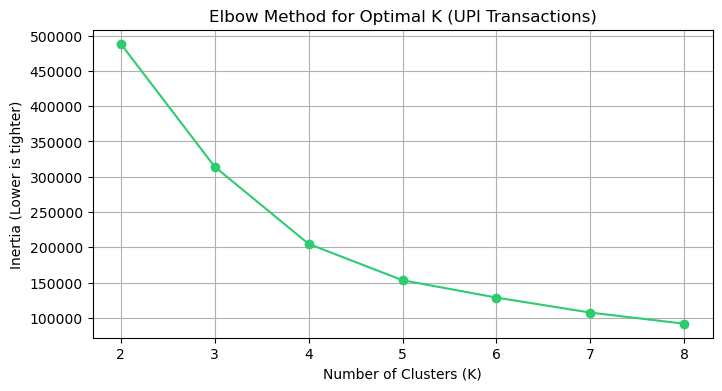

In [28]:
inertia = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertia, marker="o", color="#2ecc71")
plt.title("Elbow Method for Optimal K (UPI Transactions)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Lower is tighter)")
plt.grid(True)
plt.show()

In [34]:
best_k = 5
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
data["cluster"] = kmeans.fit_predict(X_scaled)

print("Transactions per cluster:\n", data["cluster"].value_counts().sort_index())

Transactions per cluster:
 cluster
0    62571
1    72618
2     1805
3    52945
4    60061
Name: count, dtype: int64


In [36]:
profile = data.groupby("cluster").agg(
    txn_count=("amount_inr", "count"),
    median_amount_inr=("amount_inr", "median"),
    mean_amount_inr=("amount_inr", "mean"),
    avg_hour=("hour", "mean"),
    top_category=("merchant_category", lambda x: x.mode()[0]),
    top_bank=("sender_bank", lambda x: x.mode()[0])
).round(2)

profile

,txn_count,median_amount_inr,mean_amount_inr,avg_hour,top_category,top_bank
cluster,,,,,,
0,62571,1682.0,2259.77,18.64,Grocery,SBI
1,72618,304.0,324.43,18.67,Food,SBI
2,1805,12258.0,13397.20,14.77,Education,SBI
3,52945,1668.0,2254.98,9.94,Grocery,SBI
4,60061,303.0,323.20,9.91,Food,SBI


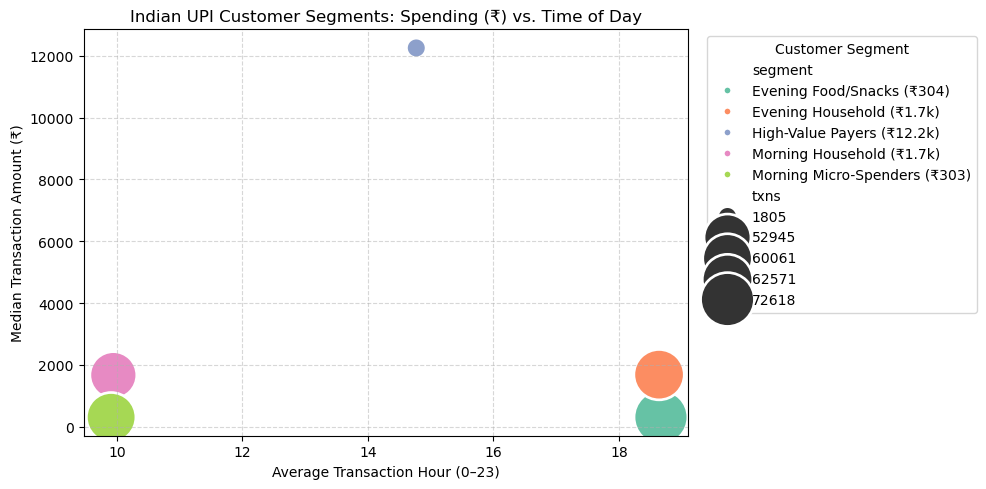

In [41]:
segment_names = {
    0: "Evening Household (₹1.7k)",
    1: "Evening Food/Snacks (₹304)",
    2: "High-Value Payers (₹12.2k)",
    3: "Morning Household (₹1.7k)",
    4: "Morning Micro-Spenders (₹303)"
}

data["segment"] = data["cluster"].map(segment_names)

summary_plot = data.groupby("segment").agg(
    median_inr=("amount_inr", "median"),
    avg_hour=("hour", "mean"),
    txns=("amount_inr", "count")
).reset_index()

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=summary_plot,
    x="avg_hour",
    y="median_inr",
    size="txns",
    hue="segment",
    sizes=(200, 1500),
    palette="Set2"
)
plt.title("Indian UPI Customer Segments: Spending (₹) vs. Time of Day")
plt.xlabel("Average Transaction Hour (0–23)")
plt.ylabel("Median Transaction Amount (₹)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Customer Segment")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [44]:
import joblib
import os

os.makedirs("../backend/models", exist_ok=True)
artifact = {
    "scaler": scaler,
    "kmeans": kmeans,
    "segment_names": {
        0: "Evening Household (₹1.7k)",
        1: "Evening Food/Snacks (₹304)",
        2: "High-Value Payers (₹12.2k)",
        3: "Morning Household (₹1.7k)",
        4: "Morning Micro-Spenders (₹303)"
    }
}

joblib.dump(artifact, "/home/saurabh/AI_PROJECTS/UPI_fraud_prediction/backend/modal/upi_kmeans_artifact.joblib")
print("Saved successfully!")

Saved successfully!
